<a href="https://colab.research.google.com/github/OwenChan39/Restaurant-Review-ABSA-using-RAG-LLM-method/blob/main/main_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Restaurant Review ABSA using RAG-LLM
## Data preparation and exploratory data analysis

This notebook combines the existing **train**, **validation (dev)**, and **test** files for shared preprocessing and descriptive EDA. Their original assignments are retained in a `dataset_split` column—**no new train/test split is performed**.

**Consistent DataFrame names:**

| Name | Meaning |
|---|---|
| `train_df`, `dev_df`, `test_df` | Original files, loaded independently and left unchanged |
| `combined_df` | One row per original review, after checking and removing exact duplicates *within each split* |
| `combined_structured_df` | One row per ABSA annotation, used for all aspect-level preprocessing and visualization |

**Important research safeguard:** Although descriptive EDA covers all three splits, **never use the test labels for fitting, retrieval, prompt tuning, or model selection**. RAG retrieval examples should be drawn from the **Train** split; use **Validation** to develop methods and **Test** only for final evaluation.

## 1. Import libraries and load the data
The loading cell below retains your existing working GitHub approach.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ast
from pathlib import Path

pd.set_option("display.max_colwidth", 100)

In [2]:
# GitHub raw data URL
base_url = "https://raw.githubusercontent.com/OwenChan39/Restaurant-Review-ABSA-using-RAG-LLM-method/main/data/"

# Load datasets
train_df = pd.read_csv(base_url + "train.txt", sep="####", header=None, names=["review", "labels"], engine="python")
test_df = pd.read_csv(base_url + "test.txt", sep="####", header=None, names=["review", "labels"], engine="python")
dev_df = pd.read_csv(base_url + "dev.txt", sep="####", header=None, names=["review", "labels"], engine="python")

# Check dimensions
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
print("Validation dataset:", dev_df.shape)

# Preview
display(train_df.head())

Training dataset: (1264, 2)
Testing dataset: (544, 2)
Validation dataset: (316, 2)


,review,labels
0,We have gone for dinner only a few times but the same great quality and service is given .,"[['service', 'service general', 'positive'], ['dinner', 'food quality', 'positive']]"
1,"Its dark , and cozy . . there is always jazz music playing when we go .","[['NULL', 'ambience general', 'positive']]"
2,This place has great indian chinese food .,"[['indian chinese food', 'food quality', 'positive']]"
3,Not what I would expect for the price and prestige of this location .,"[['location', 'restaurant prices', 'neutral'], ['location', 'restaurant miscellaneous', 'neutral']]"
4,Finally a reliable Chinese restaurant !,"[['Chinese restaurant', 'restaurant general', 'positive']]"


## 2. Combine the existing splits
This is **concatenation, not resplitting**. Every review is tagged with its original source: `Train`, `Validation`, or `Test`. We do not change the three loaded source DataFrames.

In [3]:
split_order = ["Train", "Validation", "Test"]

combined_df = pd.concat(
    [
        train_df.assign(dataset_split="Train"),
        dev_df.assign(dataset_split="Validation"),
        test_df.assign(dataset_split="Test"),
    ],
    ignore_index=True
)[["dataset_split", "review", "labels"]]

print("Combined dataset (before deduplication):", combined_df.shape)
print(combined_df["dataset_split"].value_counts().reindex(split_order))
display(combined_df.head())

Combined dataset (before deduplication): (2124, 3)
dataset_split
Train         1264
Validation     316
Test           544
Name: count, dtype: int64


,dataset_split,review,labels
0,Train,We have gone for dinner only a few times but the same great quality and service is given .,"[['service', 'service general', 'positive'], ['dinner', 'food quality', 'positive']]"
1,Train,"Its dark , and cozy . . there is always jazz music playing when we go .","[['NULL', 'ambience general', 'positive']]"
2,Train,This place has great indian chinese food .,"[['indian chinese food', 'food quality', 'positive']]"
3,Train,Not what I would expect for the price and prestige of this location .,"[['location', 'restaurant prices', 'neutral'], ['location', 'restaurant miscellaneous', 'neutral']]"
4,Train,Finally a reliable Chinese restaurant !,"[['Chinese restaurant', 'restaurant general', 'positive']]"


## 3. Data quality and exact duplicate handling (before label structuring)
Check every source column. An **exact duplicate** is the same `dataset_split`, `review`, and `labels`. The split is part of the duplicate key so that a matching record in two official splits is **not silently removed**. Repeated review texts with different labels are kept for inspection.

In [4]:
# Null and blank checks across every column of the combined source data
source_quality = pd.DataFrame([
    {
        "column": column,
        "missing_values": int(combined_df[column].isna().sum()),
        "blank_strings": int(combined_df[column].map(
            lambda value: isinstance(value, str) and not value.strip()
        ).sum()),
    }
    for column in combined_df.columns
])
display(source_quality)

# Check duplicates before dropping anything
source_key = ["dataset_split", "review", "labels"]
exact_duplicate_mask = combined_df.duplicated(subset=source_key, keep=False)

exact_duplicate_summary = pd.DataFrame({
    "dataset_split": split_order,
    "duplicate_copies_beyond_first": [
        int(combined_df.loc[combined_df["dataset_split"].eq(split)]
            .duplicated(subset=source_key).sum())
        for split in split_order
    ]
})
display(exact_duplicate_summary)

print("Rows involved in exact-duplicate groups:", int(exact_duplicate_mask.sum()))
if exact_duplicate_mask.any():
    display(combined_df.loc[exact_duplicate_mask].sort_values(source_key))

,column,missing_values,blank_strings
0,dataset_split,0,0
1,review,0,0
2,labels,0,0


,dataset_split,duplicate_copies_beyond_first
0,Train,1
1,Validation,0
2,Test,0


Rows involved in exact-duplicate groups: 2


,dataset_split,review,labels
817,Train,I love it .,"[['NULL', 'restaurant general', 'positive']]"
1005,Train,I love it .,"[['NULL', 'restaurant general', 'positive']]"


In [5]:
# Remove only exact duplicates *within* each original split
before_counts = combined_df["dataset_split"].value_counts().reindex(split_order, fill_value=0)

combined_df = (
    combined_df.drop_duplicates(subset=["dataset_split", "review", "labels"])
    .reset_index(drop=True)
)

# Create a globally unique identifier AFTER deduplication
combined_df.insert(0, "review_id", range(len(combined_df)))

after_counts = combined_df["dataset_split"].value_counts().reindex(split_order, fill_value=0)
display(pd.DataFrame({
    "before": before_counts,
    "removed": before_counts - after_counts,
    "after": after_counts,
}))

assert not combined_df.duplicated(
    subset=["dataset_split", "review", "labels"]
).any()
print("Combined review-level dataset:", combined_df.shape)
display(combined_df.head())

,before,removed,after
dataset_split,,,
Train,1264,1,1263
Validation,316,0,316
Test,544,0,544


Combined review-level dataset: (2123, 4)


,review_id,dataset_split,review,labels
0,0,Train,We have gone for dinner only a few times but the same great quality and service is given .,"[['service', 'service general', 'positive'], ['dinner', 'food quality', 'positive']]"
1,1,Train,"Its dark , and cozy . . there is always jazz music playing when we go .","[['NULL', 'ambience general', 'positive']]"
2,2,Train,This place has great indian chinese food .,"[['indian chinese food', 'food quality', 'positive']]"
3,3,Train,Not what I would expect for the price and prestige of this location .,"[['location', 'restaurant prices', 'neutral'], ['location', 'restaurant miscellaneous', 'neutral']]"
4,4,Train,Finally a reliable Chinese restaurant !,"[['Chinese restaurant', 'restaurant general', 'positive']]"


### Additional checks: repeated text and overlap across official splits
Same text with different labels is **not** the same as an exact duplicate. Show it rather than removing it. Cross-split review overlap is also reported, because it could cause retrieval leakage later.

In [6]:
# Display full review sentences
pd.set_option("display.max_colwidth", None)

# 1. Check repeated reviews WITHIN the same split
repeated_review_mask = combined_df.duplicated(
    subset=["dataset_split", "review"],
    keep=False
)

print("Repeated reviews within the same split:",
      int(repeated_review_mask.sum()))

if repeated_review_mask.any():
    display(
        combined_df.loc[repeated_review_mask].sort_values(
            ["dataset_split", "review"]
        )
    )
else:
    print("No repeated reviews within the same split.")


# 2. Check overlapping reviews BETWEEN different splits
review_sets = {
    split: set(
        combined_df.loc[
            combined_df["dataset_split"].eq(split), "review"
        ]
        .dropna().astype(str).str.strip().str.casefold()
    )
    for split in split_order
}

split_pairs = [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]

# Temporary normalized text for matching
comparison_df = combined_df.copy()
comparison_df["review_key"] = (
    comparison_df["review"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

# Display actual overlapping reviews
for split1, split2 in split_pairs:
    shared_reviews = review_sets[split1] & review_sets[split2]

    print(f"\n{split1} vs {split2}")
    print(f"Overlapping reviews: {len(shared_reviews)}")

    if shared_reviews:
        overlapping_rows = comparison_df[
            comparison_df["dataset_split"].isin([split1, split2])
            & comparison_df["review_key"].isin(shared_reviews)
        ]

        display(
            overlapping_rows[
                ["dataset_split", "review", "labels"]
            ].sort_values(["review", "dataset_split"])
        )
    else:
        print("No overlapping reviews found.")

Repeated reviews within the same split: 0
No repeated reviews within the same split.

Train vs Validation
Overlapping reviews: 2


,dataset_split,review,labels
192,Train,Awesome,"[['NULL', 'restaurant general', 'positive']]"
1212,Train,Loved It,"[['NULL', 'restaurant general', 'positive']]"
1267,Validation,Loved it,"[['NULL', 'restaurant general', 'positive']]"
1357,Validation,awesome,"[['NULL', 'restaurant general', 'positive']]"



Train vs Test
Overlapping reviews: 3


,dataset_split,review,labels
1248,Train,I lOVE THIS PLACE !,"[['PLACE', 'restaurant general', 'positive']]"
1837,Test,The atmosphere was great .,"[['atmosphere', 'ambience general', 'positive']]"
136,Train,The atmosphere was great .,"[['atmosphere', 'ambience general', 'positive']]"
1587,Test,You Ca n't Go Wrong Here .,"[['NULL', 'restaurant general', 'positive']]"
179,Train,You ca n't go wrong here .,"[['NULL', 'restaurant general', 'positive']]"
2120,Test,i love this place !,"[['place', 'restaurant general', 'positive']]"



Validation vs Test
Overlapping reviews: 0
No overlapping reviews found.


In [7]:

# Preserve a backup before removing overlaps
combined_df_backup = combined_df.copy()

# Normalize review sentences for comparison
combined_df["_review_key"] = (
    combined_df["review"]
    .astype("string")
    .str.strip()
    .str.casefold()
)

# Get unique reviews from Train and Validation
train_reviews = set(
    combined_df.loc[
        combined_df["dataset_split"] == "Train", "_review_key"
    ].dropna()
)

validation_reviews = set(
    combined_df.loc[
        combined_df["dataset_split"] == "Validation", "_review_key"
    ].dropna()
)

# Identify overlapping records to remove
remove_mask = (
    (
        (combined_df["dataset_split"] == "Validation")
        & combined_df["_review_key"].isin(train_reviews)
    )
    |
    (
        (combined_df["dataset_split"] == "Test")
        & combined_df["_review_key"].isin(
            train_reviews | validation_reviews
        )
    )
)

# Display records being removed
removed_records = combined_df.loc[remove_mask].copy()

print("Records to be removed:", len(removed_records))
display(removed_records[["dataset_split", "review", "labels"]])

# Remove overlapping records
combined_df = (
    combined_df.loc[~remove_mask]
    .drop(columns=["_review_key"])
    .reset_index(drop=True)
)

# Display updated dataset sizes
print("\nDataset sizes after overlap removal:")
print(combined_df["dataset_split"].value_counts())
print("\nTotal remaining reviews:", len(combined_df))

Records to be removed: 5


,dataset_split,review,labels
1267,Validation,Loved it,"[['NULL', 'restaurant general', 'positive']]"
1357,Validation,awesome,"[['NULL', 'restaurant general', 'positive']]"
1587,Test,You Ca n't Go Wrong Here .,"[['NULL', 'restaurant general', 'positive']]"
1837,Test,The atmosphere was great .,"[['atmosphere', 'ambience general', 'positive']]"
2120,Test,i love this place !,"[['place', 'restaurant general', 'positive']]"



Dataset sizes after overlap removal:
dataset_split
Train         1263
Test           541
Validation     314
Name: count, dtype: int64

Total remaining reviews: 2118


In [8]:
review_sets = {
    split: set(
        combined_df.loc[
            combined_df["dataset_split"] == split, "review"
        ]
        .dropna()
        .astype(str)
        .str.strip()
        .str.casefold()
    )
    for split in ["Train", "Validation", "Test"]
}

print("Train vs Validation:",
      len(review_sets["Train"] & review_sets["Validation"]))

print("Train vs Test:",
      len(review_sets["Train"] & review_sets["Test"]))

print("Validation vs Test:",
      len(review_sets["Validation"] & review_sets["Test"]))

Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0


## 4. Structure the annotations
Convert the serialized `labels` lists to long format. Each aspect annotation becomes a row in `combined_structured_df`, linked to its review using the **globally unique** `review_id` and original `dataset_split`.

If a review contains **zero annotations**, it remains in `combined_df` and is reported; no imaginary annotation is added.

In [9]:
def structure_absa_data(review_df):
    rows = []
    unannotated_review_ids = []

    for row in review_df.itertuples(index=False):
        try:
            annotations = (
                ast.literal_eval(row.labels)
                if isinstance(row.labels, str) else row.labels
            )
        except (ValueError, SyntaxError, TypeError) as exc:
            raise ValueError(f"Cannot parse labels for review_id={row.review_id}") from exc

        if not isinstance(annotations, list):
            raise ValueError(f"Labels must be a list for review_id={row.review_id}")
        if not annotations:
            unannotated_review_ids.append(row.review_id)
            continue

        for annotation in annotations:
            if (
                not isinstance(annotation, (list, tuple))
                or len(annotation) != 3
                or not all(isinstance(value, str) for value in annotation)
            ):
                raise ValueError(
                    f"Invalid annotation for review_id={row.review_id}: {annotation!r}"
                )

            aspect_term, aspect_category, sentiment = annotation
            rows.append({
                "review_id": row.review_id,
                "dataset_split": row.dataset_split,
                "review": row.review,
                "aspect_term": aspect_term,
                "aspect_category": aspect_category,
                "sentiment": sentiment,
            })

    columns = [
        "review_id", "dataset_split", "review",
        "aspect_term", "aspect_category", "sentiment"
    ]
    return pd.DataFrame(rows, columns=columns), unannotated_review_ids

combined_structured_df, unannotated_review_ids = structure_absa_data(combined_df)

# Verify that the count of annotations was preserved
expected_annotations = sum(
    len(ast.literal_eval(labels)) if isinstance(labels, str) else len(labels)
    for labels in combined_df["labels"]
)
assert len(combined_structured_df) == expected_annotations

print("Reviews:", len(combined_df))
print("Aspect annotations:", len(combined_structured_df))
print("Reviews without annotations:", len(unannotated_review_ids))
display(combined_structured_df.head(10))

Reviews: 2118
Aspect annotations: 3289
Reviews without annotations: 0


,review_id,dataset_split,review,aspect_term,aspect_category,sentiment
0,0,Train,We have gone for dinner only a few times but the same great quality and service is given .,service,service general,positive
1,0,Train,We have gone for dinner only a few times but the same great quality and service is given .,dinner,food quality,positive
2,1,Train,"Its dark , and cozy . . there is always jazz music playing when we go .",NULL,ambience general,positive
3,2,Train,This place has great indian chinese food .,indian chinese food,food quality,positive
4,3,Train,Not what I would expect for the price and prestige of this location .,location,restaurant prices,neutral
5,3,Train,Not what I would expect for the price and prestige of this location .,location,restaurant miscellaneous,neutral
6,4,Train,Finally a reliable Chinese restaurant !,Chinese restaurant,restaurant general,positive
7,5,Train,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food style_options,neutral
8,5,Train,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food quality,negative
9,6,Train,The menu is fairly simple without much descriptions .,menu,food style_options,neutral


In [10]:
for col in ["aspect_term", "aspect_category", "sentiment"]:
    print(f"\n{'='*60}")
    print(f"Value counts for: {col}")
    print(f"{'='*60}")

    value_counts_df = (
        combined_structured_df[col]
        .fillna("<NA>")
        .astype(str)
        .value_counts(dropna=False)
        .reset_index()
    )

    value_counts_df.columns = [col, "count"]
    display(value_counts_df)


Value counts for: aspect_term


,aspect_term,count
0,NULL,725
1,food,282
2,service,179
3,place,154
4,restaurant,63
...,...,...
892,pork croquette sandwich,1
893,dhal,1
894,artwork,1
895,lemon chicken,1



Value counts for: aspect_category


,aspect_category,count
0,food quality,1180
1,service general,582
2,restaurant general,499
3,ambience general,354
4,food style_options,181
5,restaurant miscellaneous,118
6,food prices,102
7,restaurant prices,96
8,drinks quality,68
9,drinks style_options,46



Value counts for: sentiment


,sentiment,count
0,positive,2287
1,negative,877
2,neutral,125


## 5. Preprocess the combined structured dataset
Keep original review text unchanged. Standardize category/sentiment labels and convert the dataset convention `"NULL"` to an **empty aspect term `""`** for implicit aspects. This is an intentional label, **not** a missing review or an error.

In [11]:
# Preserve review text and original source labels in combined_df
combined_structured_df["aspect_term"] = (
    combined_structured_df["aspect_term"].str.strip()
)
combined_structured_df["aspect_term"] = combined_structured_df["aspect_term"].mask(
    combined_structured_df["aspect_term"].str.casefold().eq("null"),
    ""
)

combined_structured_df["aspect_category"] = (
    combined_structured_df["aspect_category"].str.strip().str.lower()
)
combined_structured_df["sentiment"] = (
    combined_structured_df["sentiment"].str.strip().str.lower()
)

combined_structured_df["aspect_type"] = np.where(
    combined_structured_df["aspect_term"].eq(""),
    "Implicit", "Explicit"
)

print("Processed annotation columns:", combined_structured_df.columns.tolist())
display(combined_structured_df.head(10))

Processed annotation columns: ['review_id', 'dataset_split', 'review', 'aspect_term', 'aspect_category', 'sentiment', 'aspect_type']


,review_id,dataset_split,review,aspect_term,aspect_category,sentiment,aspect_type
0,0,Train,We have gone for dinner only a few times but the same great quality and service is given .,service,service general,positive,Explicit
1,0,Train,We have gone for dinner only a few times but the same great quality and service is given .,dinner,food quality,positive,Explicit
2,1,Train,"Its dark , and cozy . . there is always jazz music playing when we go .",,ambience general,positive,Implicit
3,2,Train,This place has great indian chinese food .,indian chinese food,food quality,positive,Explicit
4,3,Train,Not what I would expect for the price and prestige of this location .,location,restaurant prices,neutral,Explicit
5,3,Train,Not what I would expect for the price and prestige of this location .,location,restaurant miscellaneous,neutral,Explicit
6,4,Train,Finally a reliable Chinese restaurant !,Chinese restaurant,restaurant general,positive,Explicit
7,5,Train,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food style_options,neutral,Explicit
8,5,Train,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food quality,negative,Explicit
9,6,Train,The menu is fairly simple without much descriptions .,menu,food style_options,neutral,Explicit


## 6. Post-structuring quality assessment
Assess **all** columns of the processed annotation table. Blank `aspect_term` values are counted for transparency but are **valid implicit aspects**. Identical annotation triplets for the same `review_id` are reported, **not automatically deleted**: some source labels contain repeated triplets.

In [12]:
# Check missing and blank entries across ALL columns
structured_quality = pd.DataFrame([
    {
        "column": column,
        "missing_values": int(combined_structured_df[column].isna().sum()),
        "blank_strings": int(combined_structured_df[column].map(
            lambda value: isinstance(value, str) and not value.strip()
        ).sum()),
    }
    for column in combined_structured_df.columns
])
display(structured_quality)

# Check invalid values and duplicate annotation triplets
valid_sentiments = {"positive", "negative", "neutral"}
invalid_sentiment_mask = ~combined_structured_df["sentiment"].isin(valid_sentiments)
blank_category_mask = combined_structured_df["aspect_category"].eq("")
annotation_key = ["review_id", "aspect_term", "aspect_category", "sentiment"]
duplicate_annotation_mask = combined_structured_df.duplicated(
    subset=annotation_key, keep=False
)

print("Invalid sentiment annotations:", int(invalid_sentiment_mask.sum()))
print("Blank aspect categories:", int(blank_category_mask.sum()))
print("Repeated annotation triplet groups (rows):", int(duplicate_annotation_mask.sum()))
print("Implicit aspect annotations:", int(combined_structured_df["aspect_type"].eq("Implicit").sum()))

if invalid_sentiment_mask.any():
    display(combined_structured_df.loc[invalid_sentiment_mask])
if blank_category_mask.any():
    display(combined_structured_df.loc[blank_category_mask])
if duplicate_annotation_mask.any():
    display(combined_structured_df.loc[duplicate_annotation_mask].sort_values(annotation_key).head(50))

,column,missing_values,blank_strings
0,review_id,0,0
1,dataset_split,0,0
2,review,0,0
3,aspect_term,0,725
4,aspect_category,0,0
5,sentiment,0,0
6,aspect_type,0,0


Invalid sentiment annotations: 0
Blank aspect categories: 0
Repeated annotation triplet groups (rows): 426
Implicit aspect annotations: 725


,review_id,dataset_split,review,aspect_term,aspect_category,sentiment,aspect_type
21,12,Train,"Excellent atmosphere , delicious dishes good and friendly service .",service,service general,positive,Explicit
22,12,Train,"Excellent atmosphere , delicious dishes good and friendly service .",service,service general,positive,Explicit
39,24,Train,"Sometimes tables do n't understand his sense of humor but it 's refreshing to have a server who has personality , professionalism , and respects the privacy of your dinner .",server,service general,positive,Explicit
40,24,Train,"Sometimes tables do n't understand his sense of humor but it 's refreshing to have a server who has personality , professionalism , and respects the privacy of your dinner .",server,service general,positive,Explicit
41,24,Train,"Sometimes tables do n't understand his sense of humor but it 's refreshing to have a server who has personality , professionalism , and respects the privacy of your dinner .",server,service general,positive,Explicit
51,31,Train,"The place is small and intimate and you may feel a little crowded , but the service is excellent and it 's great for friends out , a romantic date , or a special occassion .",place,restaurant miscellaneous,positive,Explicit
52,31,Train,"The place is small and intimate and you may feel a little crowded , but the service is excellent and it 's great for friends out , a romantic date , or a special occassion .",place,restaurant miscellaneous,positive,Explicit
58,36,Train,"Creative , consistent , fresh .",,food quality,positive,Implicit
60,36,Train,"Creative , consistent , fresh .",,food quality,positive,Implicit
70,42,Train,Service was prompt and courteous .,Service,service general,positive,Explicit


In [13]:
# Backup the structured dataset before deduplication
combined_structured_backup = combined_structured_df.copy()

In [14]:
# Define columns used to identify duplicate annotations
duplicate_columns = [
    "review_id",
    "dataset_split",
    "aspect_term",
    "aspect_category",
    "sentiment"
]

# Count duplicate annotations
duplicates_before = combined_structured_df.duplicated(
    subset=duplicate_columns
).sum()

print("Annotations before:", len(combined_structured_df))
print("Duplicate annotations found:", duplicates_before)

# Remove duplicate annotations, keeping the first occurrence
combined_structured_df = (
    combined_structured_df
    .drop_duplicates(subset=duplicate_columns, keep="first")
    .reset_index(drop=True)
)

# Verify results
print("\nAfter Duplicate Removal")
print("Annotations after:", len(combined_structured_df))
print("Annotations removed:", duplicates_before)
print(
    "Remaining duplicates:",
    combined_structured_df.duplicated(
        subset=duplicate_columns
    ).sum()
)

# Preview
display(combined_structured_df.head(10))

Annotations before: 3289
Duplicate annotations found: 229

After Duplicate Removal
Annotations after: 3060
Annotations removed: 229
Remaining duplicates: 0


,review_id,dataset_split,review,aspect_term,aspect_category,sentiment,aspect_type
0,0,Train,We have gone for dinner only a few times but the same great quality and service is given .,service,service general,positive,Explicit
1,0,Train,We have gone for dinner only a few times but the same great quality and service is given .,dinner,food quality,positive,Explicit
2,1,Train,"Its dark , and cozy . . there is always jazz music playing when we go .",,ambience general,positive,Implicit
3,2,Train,This place has great indian chinese food .,indian chinese food,food quality,positive,Explicit
4,3,Train,Not what I would expect for the price and prestige of this location .,location,restaurant prices,neutral,Explicit
5,3,Train,Not what I would expect for the price and prestige of this location .,location,restaurant miscellaneous,neutral,Explicit
6,4,Train,Finally a reliable Chinese restaurant !,Chinese restaurant,restaurant general,positive,Explicit
7,5,Train,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food style_options,neutral,Explicit
8,5,Train,"The lobster knuckles ( special of the day ) were ok , but pretty tasteless .",lobster knuckles,food quality,negative,Explicit
9,6,Train,The menu is fairly simple without much descriptions .,menu,food style_options,neutral,Explicit


## 7. Exploratory data analysis — all original splits combined
All charts below use the same `combined_structured_df` annotation table, with `combined_df` used **only** for review-level statistics (one record per review). The EDA is descriptive; keep test information out of modeling decisions.

### 7.1 Dataset overview
Review counts and annotation counts are different: a review can contain multiple aspects.

In [15]:
review_counts = (
    combined_df.groupby("dataset_split").size()
    .reindex(split_order, fill_value=0)
)
annotation_counts = (
    combined_structured_df.groupby("dataset_split").size()
    .reindex(split_order, fill_value=0)
)

split_summary = pd.DataFrame({
    "Reviews": review_counts,
    "Annotations": annotation_counts,
    "Avg Annotations per Review": (annotation_counts / review_counts).round(2),
})
split_summary.loc["Total"] = [
    review_counts.sum(),
    annotation_counts.sum(),
    round(annotation_counts.sum() / review_counts.sum(), 2),
]
display(split_summary)

,Reviews,Annotations,Avg Annotations per Review
dataset_split,,,
Train,1263.0,1837.0,1.45
Validation,314.0,457.0,1.46
Test,541.0,766.0,1.42
Total,2118.0,3060.0,1.44


### 7.2 Positive, negative, and neutral sentiments
- **Unique reviews:** number of distinct reviews containing *at least one* annotation of that sentiment. A review may appear in multiple categories, so these counts do not necessarily sum to the total number of reviews.
- **Annotations:** each aspect–category–sentiment annotation counted separately. These counts sum to the number of annotations.

,Unique Reviews,Annotations,% of Annotations
sentiment,,,
positive,1502,2112,69.02
negative,660,829,27.09
neutral,111,119,3.89


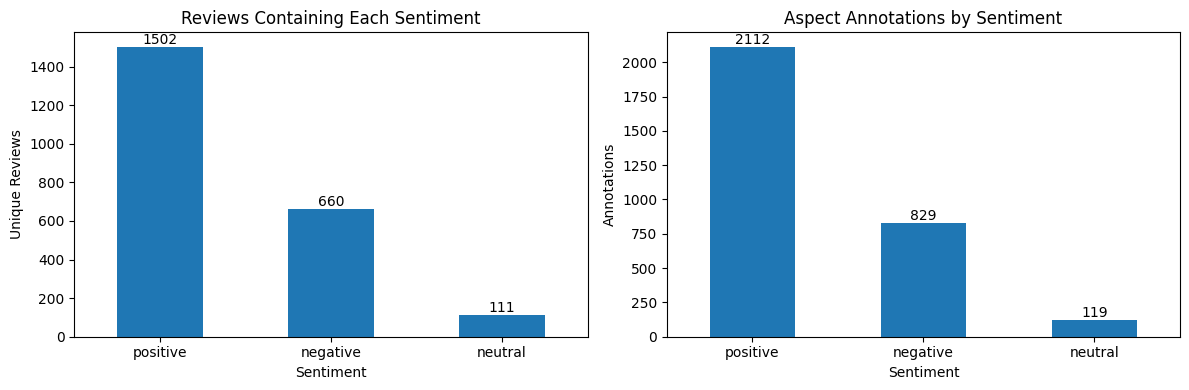

In [16]:
sentiment_order = ["positive", "negative", "neutral"]

review_sentiment_counts = (
    combined_structured_df.groupby("sentiment")["review_id"]
    .nunique().reindex(sentiment_order, fill_value=0)
)
annotation_sentiment_counts = (
    combined_structured_df["sentiment"]
    .value_counts().reindex(sentiment_order, fill_value=0)
)

sentiment_summary = pd.DataFrame({
    "Unique Reviews": review_sentiment_counts,
    "Annotations": annotation_sentiment_counts,
    "% of Annotations": (
        100 * annotation_sentiment_counts / len(combined_structured_df)
    ).round(2),
})
display(sentiment_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
review_sentiment_counts.plot(kind="bar", ax=axes[0])
axes[0].set(title="Reviews Containing Each Sentiment", xlabel="Sentiment", ylabel="Unique Reviews")
axes[0].tick_params(axis="x", rotation=0)
axes[0].bar_label(axes[0].containers[0])

annotation_sentiment_counts.plot(kind="bar", ax=axes[1])
axes[1].set(title="Aspect Annotations by Sentiment", xlabel="Sentiment", ylabel="Annotations")
axes[1].tick_params(axis="x", rotation=0)
axes[1].bar_label(axes[1].containers[0])
plt.tight_layout()
plt.show()

### 7.3 Top 10 aspect categories
Rank by the number of **unique reviews** mentioning each category; also show annotation counts for context.

,Unique_Reviews,Annotations
aspect_category,,
food quality,873,1093
service general,491,521
restaurant general,486,487
ambience general,270,303
food style_options,157,172
restaurant miscellaneous,115,115
restaurant prices,96,96
food prices,94,102
drinks quality,64,66


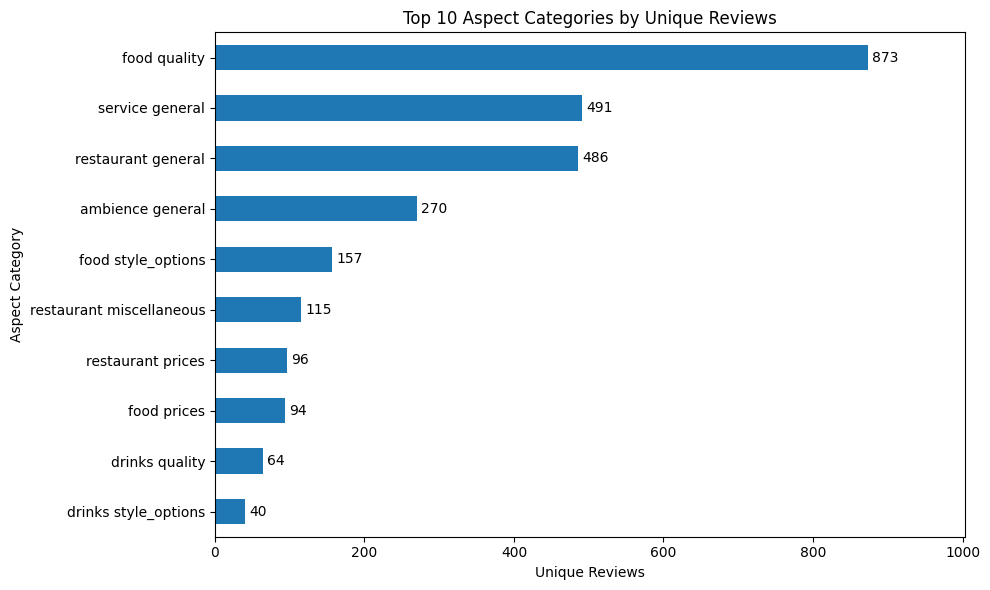

In [17]:
category_summary = (
    combined_structured_df.groupby("aspect_category")
    .agg(Unique_Reviews=("review_id", "nunique"), Annotations=("sentiment", "size"))
    .sort_values(["Unique_Reviews", "Annotations"], ascending=False)
    .head(10)
)
display(category_summary)

ax = category_summary["Unique_Reviews"].iloc[::-1].plot(
    kind="barh", figsize=(10, 6)
)
ax.set(title="Top 10 Aspect Categories by Unique Reviews", xlabel="Unique Reviews", ylabel="Aspect Category")
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlim(0, max(category_summary["Unique_Reviews"]) * 1.15)
plt.tight_layout()
plt.show()

### 7.4 Top 10 explicit aspect terms
Exclude blank/implicit terms. Normalize casing **for counting only**; don't alter the original annotated terms.

,Annotations
aspect_term,
food,291
service,186
place,151
restaurant,61
sushi,46
staff,45
pizza,42
atmosphere,38
decor,26


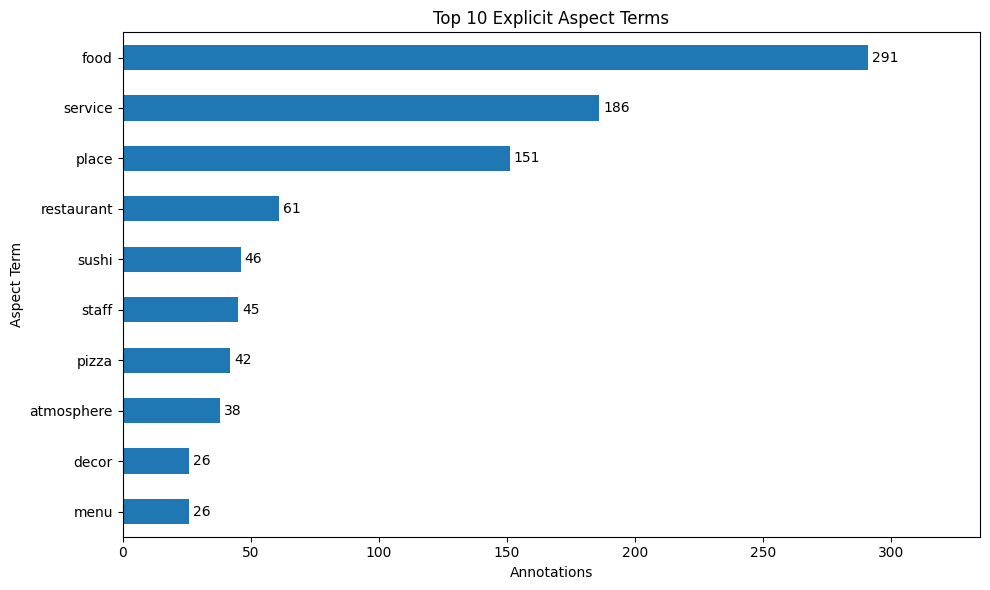

In [18]:
explicit_terms = (
    combined_structured_df.loc[
        combined_structured_df["aspect_type"].eq("Explicit"), "aspect_term"
    ].str.casefold().str.strip()
)
top10_terms = explicit_terms.value_counts().head(10)
display(top10_terms.to_frame("Annotations"))

ax = top10_terms.iloc[::-1].plot(kind="barh", figsize=(10, 6))
ax.set(title="Top 10 Explicit Aspect Terms", xlabel="Annotations", ylabel="Aspect Term")
ax.bar_label(ax.containers[0], padding=3)
ax.set_xlim(0, max(top10_terms) * 1.15)
plt.tight_layout()
plt.show()

### 7.5 Sentiment composition across the most frequent aspect categories
Use the **top 10 categories by annotation frequency** and compare sentiment percentages, not only raw counts. This highlights differences between categories of different sizes.

sentiment,positive,negative,neutral
aspect_category,,,
food quality,829,224,40
service general,259,247,15
restaurant general,376,104,7
ambience general,245,45,13
food style_options,107,49,16
restaurant miscellaneous,71,36,8
food prices,44,53,5
restaurant prices,40,48,8
drinks quality,59,6,1


sentiment,positive,negative,neutral
aspect_category,,,
food quality,75.8,20.5,3.7
service general,49.7,47.4,2.9
restaurant general,77.2,21.4,1.4
ambience general,80.9,14.9,4.3
food style_options,62.2,28.5,9.3
restaurant miscellaneous,61.7,31.3,7.0
food prices,43.1,52.0,4.9
restaurant prices,41.7,50.0,8.3
drinks quality,89.4,9.1,1.5


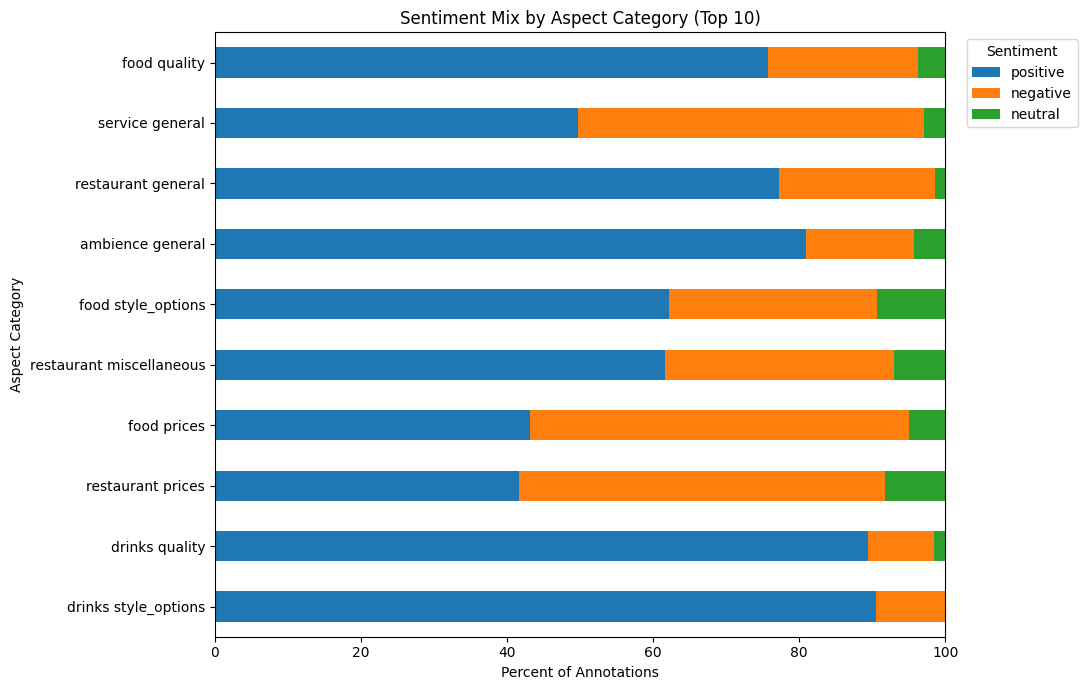

In [19]:
top10_category_names = (
    combined_structured_df["aspect_category"].value_counts().head(10).index
)
category_sentiment_counts = pd.crosstab(
    combined_structured_df["aspect_category"],
    combined_structured_df["sentiment"]
).reindex(index=top10_category_names, columns=sentiment_order, fill_value=0)

category_sentiment_percent = (
    category_sentiment_counts.div(category_sentiment_counts.sum(axis=1), axis=0) * 100
).round(1)
display(category_sentiment_counts)
display(category_sentiment_percent)

ax = category_sentiment_percent.iloc[::-1].plot(
    kind="barh", stacked=True, figsize=(11, 7)
)
ax.set(title="Sentiment Mix by Aspect Category (Top 10)", xlabel="Percent of Annotations", ylabel="Aspect Category", xlim=(0, 100))
ax.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### 7.6 Explicit versus implicit aspects
A blank aspect term (`""`) corresponds to an **implicit** aspect; it is not a missing-value error.

,Annotations,% of Annotations
aspect_type,,
Explicit,2377,77.68
Implicit,683,22.32


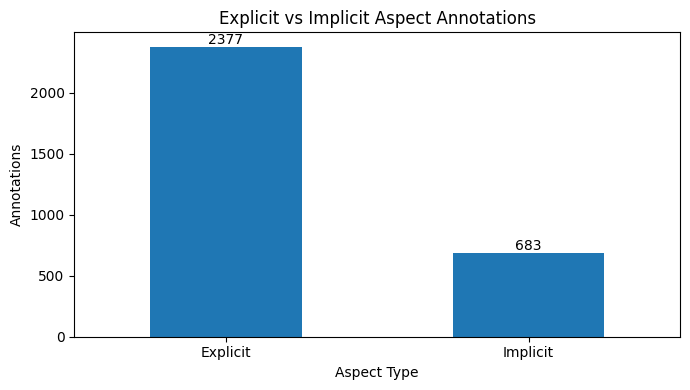

In [20]:
aspect_type_counts = (
    combined_structured_df["aspect_type"]
    .value_counts().reindex(["Explicit", "Implicit"], fill_value=0)
)
aspect_type_summary = pd.DataFrame({
    "Annotations": aspect_type_counts,
    "% of Annotations": (100 * aspect_type_counts / aspect_type_counts.sum()).round(2),
})
display(aspect_type_summary)

ax = aspect_type_counts.plot(kind="bar", figsize=(7, 4))
ax.set(title="Explicit vs Implicit Aspect Annotations", xlabel="Aspect Type", ylabel="Annotations")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

### 7.7 Number of aspect annotations per review
Group by the globally unique `review_id`, so multiple annotations for one review are counted correctly. Include zero-annotation reviews, if any.

,Number of Reviews
1,1454
2,459
3,149
4,45
5,7
6,2
7,2


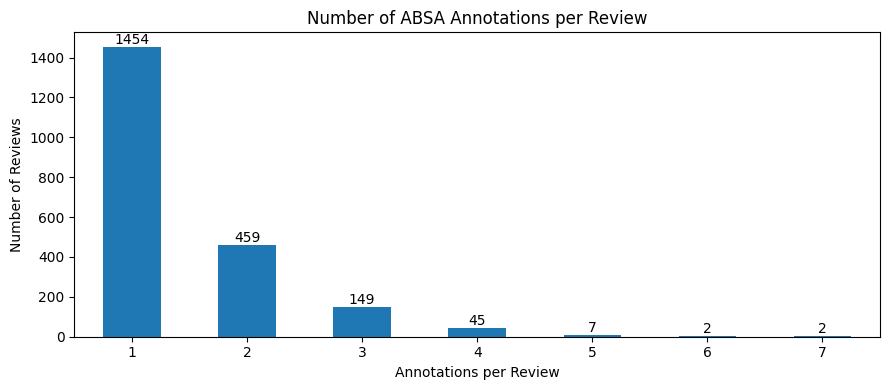

Mean: 1.44
Median: 1.0
Maximum: 7


In [21]:
aspects_per_review = (
    combined_structured_df.groupby("review_id").size()
    .reindex(combined_df["review_id"], fill_value=0)
)
aspect_count_distribution = aspects_per_review.value_counts().sort_index()
display(aspect_count_distribution.to_frame("Number of Reviews"))

ax = aspect_count_distribution.plot(kind="bar", figsize=(9, 4))
ax.set(title="Number of ABSA Annotations per Review", xlabel="Annotations per Review", ylabel="Number of Reviews")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

print("Mean:", round(aspects_per_review.mean(), 2))
print("Median:", aspects_per_review.median())
print("Maximum:", aspects_per_review.max())

### 7.8 Reviews with mixed sentiment
ABSA is particularly useful when a review contains both positive and negative aspect sentiments, or any combination of multiple sentiment polarities.

,Number of Reviews
No Annotations,0
Single Sentiment,1965
Mixed Sentiments,153


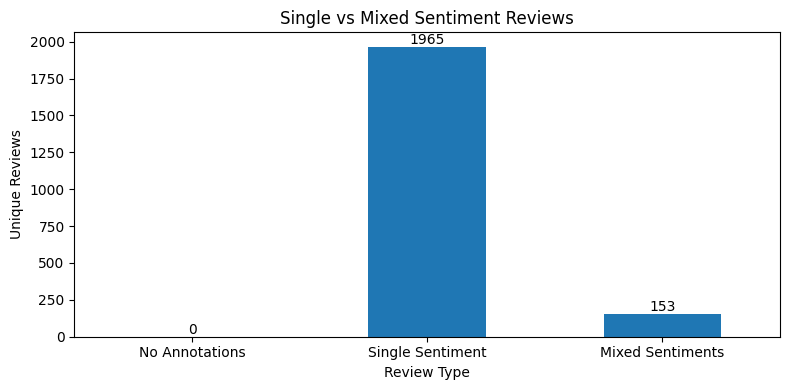

Mixed sentiment reviews: 7.22%


In [22]:
sentiment_types_per_review = (
    combined_structured_df.groupby("review_id")["sentiment"].nunique()
    .reindex(combined_df["review_id"], fill_value=0)
)
review_sentiment_type = pd.Series(
    np.select(
        [sentiment_types_per_review.eq(0), sentiment_types_per_review.eq(1)],
        ["No Annotations", "Single Sentiment"],
        default="Mixed Sentiments"
    ),
    index=combined_df["review_id"],
)
mixed_summary = review_sentiment_type.value_counts().reindex(
    ["No Annotations", "Single Sentiment", "Mixed Sentiments"], fill_value=0
)
display(mixed_summary.to_frame("Number of Reviews"))

ax = mixed_summary.plot(kind="bar", figsize=(8, 4))
ax.set(title="Single vs Mixed Sentiment Reviews", xlabel="Review Type", ylabel="Unique Reviews")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

print(f"Mixed sentiment reviews: {100 * mixed_summary['Mixed Sentiments'] / len(combined_df):.2f}%")

### 7.9 Review length distribution
Use `combined_df` because it contains **exactly one row per review** after source deduplication; using the annotation table would overcount multi-aspect reviews.

,Review Word Count
count,2118.000000
mean,14.533050
std,9.260753
min,1.000000
25%,8.000000
50%,13.000000
75%,19.000000
max,78.000000


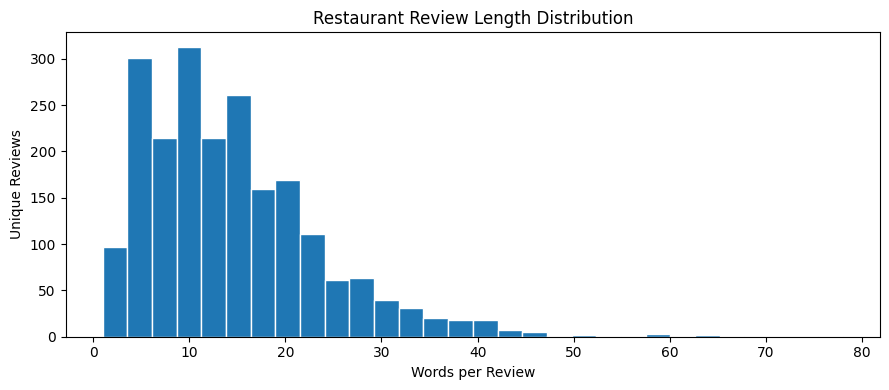

In [23]:
review_lengths = combined_df["review"].fillna("").str.split().str.len()
display(review_lengths.describe().to_frame("Review Word Count"))

plt.figure(figsize=(9, 4))
plt.hist(review_lengths, bins=30, edgecolor="white")
plt.title("Restaurant Review Length Distribution")
plt.xlabel("Words per Review")
plt.ylabel("Unique Reviews")
plt.tight_layout()
plt.show()

### 7.10 Sentiment distribution by original dataset split
A useful **descriptive** check to see whether the train, validation, and test sets differ in label mix. Do not use the test results to choose prompts, retrieval strategies, or model hyperparameters.

sentiment,positive,negative,neutral
dataset_split,,,
Train,1254,525,58
Validation,304,130,23
Test,554,174,38


sentiment,positive,negative,neutral
dataset_split,,,
Train,68.3,28.6,3.2
Validation,66.5,28.4,5.0
Test,72.3,22.7,5.0


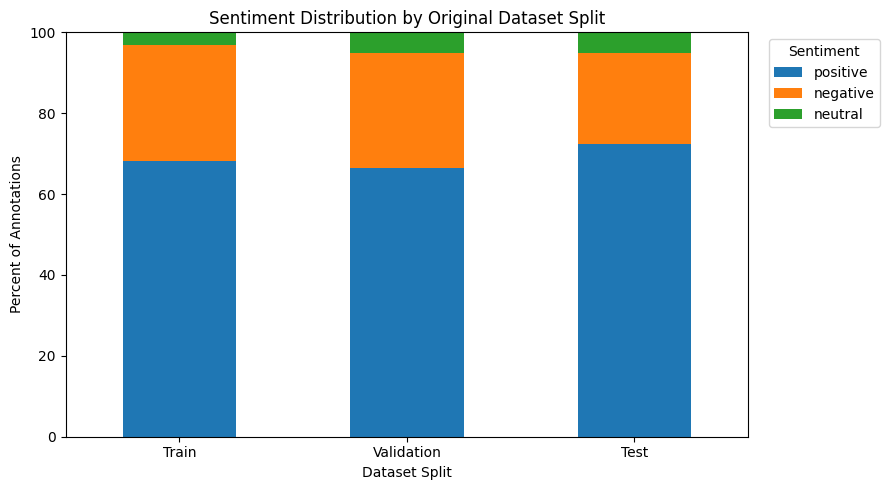

In [24]:
split_sentiment_counts = pd.crosstab(
    combined_structured_df["dataset_split"],
    combined_structured_df["sentiment"]
).reindex(index=split_order, columns=sentiment_order, fill_value=0)

split_sentiment_percent = (
    split_sentiment_counts.div(split_sentiment_counts.sum(axis=1), axis=0) * 100
).round(1)
display(split_sentiment_counts)
display(split_sentiment_percent)

ax = split_sentiment_percent.plot(kind="bar", stacked=True, figsize=(9, 5))
ax.set(title="Sentiment Distribution by Original Dataset Split", xlabel="Dataset Split", ylabel="Percent of Annotations", ylim=(0, 100))
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Sentiment", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 8. Export the combined prepared datasets
Save both the **review-level** and **annotation-level** tables. The `dataset_split` column remains in both exports so the original partitions can be selected later without any random split.

Note: when loading the annotation CSV again with Pandas, use `keep_default_na=False` so valid empty implicit aspect terms remain `""`, rather than being interpreted as missing values.

In [25]:
output_dir = Path("/content/processed_data")
output_dir.mkdir(parents=True, exist_ok=True)

review_file = output_dir / "combined_reviews.csv"
annotation_file = output_dir / "combined_annotations.csv"

combined_df.to_csv(review_file, index=False)
combined_structured_df.to_csv(annotation_file, index=False)

print("Saved:", review_file)
print("Saved:", annotation_file)

# Example for a later modeling notebook (no train_test_split needed):
# train_annotations = combined_structured_df.loc[
#     combined_structured_df["dataset_split"] == "Train"
# ].copy()
# dev_annotations = combined_structured_df.loc[
#     combined_structured_df["dataset_split"] == "Validation"
# ].copy()
# test_annotations = combined_structured_df.loc[
#     combined_structured_df["dataset_split"] == "Test"
# ].copy()

Saved: /content/processed_data/combined_reviews.csv
Saved: /content/processed_data/combined_annotations.csv


## Next stage: zero-shot and RAG-LLM experiments

- Keep all annotation labels grouped **by `review_id`** when preparing one review per model request.
- Use **Train** reviews for the retrieval knowledge base and **Validation** reviews for development.
- Keep **Test** examples out of the retrieval corpus, prompt selection, and experimental tuning; evaluate them only after decisions are finalized.
- Do **not** automatically balance the source dataset during EDA. Report class imbalance and investigate retrieval diversification as a separate modeling experiment if appropriate.

**No train/test resplitting is needed:** `dataset_split` keeps the original assignments intact.